# Tech Challenge — Fase 2 | Pré-processamento

**Projeto:** Classificação binária de qualidade do vinho — FIAP Pós-Tech Data Analytics.  
**Fonte única:** `data/raw/WineQT.csv` (não é alterada).  
**Objetivo:** preparar os dados sem vazamento e documentar a criação **experimental** de uma feature, para posterior avaliação pelos classificadores.

> Execute do começo ao fim na raiz do repositório ou na pasta `notebooks/`. A divisão treino/teste é determinística no ambiente adotado e também será registrada em CSV.

## 2.1. Variável-alvo, preditores e diagnóstico de faltantes

A variável `quality_class` é obtida pela regra 1 se `quality ≥ 7`, caso contrário 0. Não usar nem `quality` nem `Id` como preditores.

In [1]:

from pathlib import Path
import pandas as pd

# Localizar a raiz do projeto
raiz = Path.cwd().resolve()

if raiz.name == "notebooks":
    raiz = raiz.parent

# Carregar a base original
df_raw = pd.read_csv(
    raiz / "data" / "raw" / "WineQT.csv"
)

# Definir variável-alvo binária
y = (df_raw["quality"] >= 7).astype(int)

# Definir variáveis preditoras
X = df_raw.drop(columns=["Id", "quality"])

# Conferir resultado
print("Dimensões de X:", X.shape)
print("Dimensões de y:", y.shape)
print("\nDistribuição das classes:")
print(y.value_counts().sort_index())

print("\nVariáveis preditoras:")
print(X.columns.tolist())


Dimensões de X: (1143, 11)
Dimensões de y: (1143,)

Distribuição das classes:
quality
0    984
1    159
Name: count, dtype: int64

Variáveis preditoras:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']


In [2]:
# Verificar valores ausentes antes de qualquer imputação
faltantes = X.isna().sum()
print("Valores ausentes por variável:")
display(faltantes.to_frame("Qtd. ausente"))
print("Total de valores ausentes nas preditoras:", int(faltantes.sum()))
print("Valores ausentes no alvo:", int(y.isna().sum()))
assert int(faltantes.sum()) == 0 and y.notna().all()
print("Não é necessária imputação para este conjunto de dados.")

Valores ausentes por variável:


,Qtd. ausente
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


Total de valores ausentes nas preditoras: 0
Valores ausentes no alvo: 0
Não é necessária imputação para este conjunto de dados.


**Decisão:** não foram observados dados ausentes na base. Não houve exclusão de linhas nem preenchimento artificial. Outliers sinalizados na EDA foram preservados enquanto não houver evidência de erro de medição.

## 2.2. Análise de duplicações

Objetivo: investigar registros com características
físico-químicas idênticas e verificar possíveis
divergências na classificação da qualidade.

Esta análise auxiliará na definição da estratégia
de separação entre treinamento e teste.

In [3]:

# Criar uma base temporária para auditoria
dados_auditoria = X.copy()
dados_auditoria["quality_class"] = y.to_numpy()

# Duplicações considerando características e classe
duplicatas_exatas = dados_auditoria.duplicated().sum()

# Duplicações considerando apenas características
duplicatas_X = X.duplicated().sum()

# Agrupar vinhos com características idênticas
grupos = (
    dados_auditoria
    .groupby(list(X.columns), dropna=False)
    ["quality_class"]
    .agg(
        amostras="size",
        classes_distintas="nunique"
    )
)

# Identificar grupos repetidos
grupos_repetidos = grupos[
    grupos["amostras"] > 1
]

# Identificar características iguais com classes diferentes
grupos_conflitantes = grupos[
    grupos["classes_distintas"] > 1
]

print("=== AUDITORIA DE DUPLICAÇÕES ===")

print(
    "Duplicatas exatas (X + classe):",
    duplicatas_exatas
)

print(
    "Duplicatas considerando somente X:",
    duplicatas_X
)

print(
    "Grupos com características repetidas:",
    len(grupos_repetidos)
)

print(
    "Grupos com classificações divergentes:",
    len(grupos_conflitantes)
)

print(
    "Amostras em grupos divergentes:",
    int(grupos_conflitantes["amostras"].sum())
)

print("\nNenhum registro foi excluído.")


=== AUDITORIA DE DUPLICAÇÕES ===
Duplicatas exatas (X + classe): 125
Duplicatas considerando somente X: 125
Grupos com características repetidas: 114
Grupos com classificações divergentes: 0
Amostras em grupos divergentes: 0

Nenhum registro foi excluído.


### Conclusão 10 — Auditoria e tratamento de duplicações

A auditoria identificou 125 registros duplicados em relação às 11 características físico-químicas e à classificação binária da qualidade. Esses registros estão distribuídos em 114 grupos de perfis repetidos, totalizando 239 observações nesses grupos.

Não foram identificadas divergências de classificação entre observações com características físico-químicas idênticas.

Considerando a impossibilidade de determinar se os registros representam amostras físicas distintas ou duplicações de cadastro, decidiu-se preservar inicialmente todas as 1.143 observações.

Para reduzir o risco de vazamento de dados, será utilizada uma estratégia de separação em treinamento e teste que mantenha observações com características idênticas no mesmo conjunto.

Essa decisão preserva a base original e permite avaliar o comportamento dos modelos, reconhecendo que perfis repetidos podem influenciar o peso relativo de determinadas observações.

## 2.3. Separação dos dados em treinamento e teste

A separação será realizada com grupos de características
físico-químicas idênticas, evitando que essas observações
sejam distribuídas entre treinamento e teste.

Será utilizada uma divisão estratificada por grupos,
buscando preservar a proporção original das classes.

In [4]:

import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

# 1. Identificar grupos de características idênticas
grupos_id = X.groupby(
    list(X.columns),
    sort=False,
    dropna=False
).ngroup()

# 2. Configurar divisão estratificada por grupos
divisor = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 3. Selecionar uma divisão para treino e teste
idx_treino, idx_teste = next(
    divisor.split(X, y, groups=grupos_id)
)

X_train = X.iloc[idx_treino].copy()
X_test = X.iloc[idx_teste].copy()

y_train = y.iloc[idx_treino].copy()
y_test = y.iloc[idx_teste].copy()

# 4. Confirmar que nenhum grupo aparece nos dois conjuntos
grupos_treino = set(grupos_id.iloc[idx_treino])
grupos_teste = set(grupos_id.iloc[idx_teste])

grupos_compartilhados = (
    grupos_treino.intersection(grupos_teste)
)

assert len(grupos_compartilhados) == 0

print("=== SEPARAÇÃO DOS DADOS ===")
print("Amostras de treinamento:", len(X_train))
print("Amostras de teste:", len(X_test))

print(
    "Grupos presentes nos dois conjuntos:",
    len(grupos_compartilhados)
)

# 5. Verificar balanceamento após a divisão
resumo = pd.DataFrame({
    "Conjunto": ["Original", "Treino", "Teste"],
    "Amostras": [len(y), len(y_train), len(y_test)],
    "Classe 0 (%)": [
        (serie == 0).mean() * 100
        for serie in [y, y_train, y_test]
    ],
    "Classe 1 (%)": [
        (serie == 1).mean() * 100
        for serie in [y, y_train, y_test]
    ]
})

display(resumo.round(2))


=== SEPARAÇÃO DOS DADOS ===
Amostras de treinamento: 914
Amostras de teste: 229
Grupos presentes nos dois conjuntos: 0


,Conjunto,Amostras,Classe 0 (%),Classe 1 (%)
0,Original,1143,86.09,13.91
1,Treino,914,86.11,13.89
2,Teste,229,86.03,13.97


### Conclusão 11 — Separação dos dados em treinamento e teste

A divisão dos dados foi realizada utilizando a técnica `StratifiedGroupKFold`, com o objetivo de preservar a distribuição das classes e impedir que observações com características físico-químicas idênticas fossem distribuídas entre treinamento e teste.

Foram destinadas 914 amostras (79,97%) ao treinamento e 229 amostras (20,03%) ao teste.

A classe de alta qualidade representou 13,89% do conjunto de treinamento e 13,97% do conjunto de teste, mantendo proporções próximas à distribuição original de 13,91%.

Também foi confirmada a ausência de grupos compartilhados entre os conjuntos, reduzindo o risco de vazamento associado aos registros duplicados.

A divisão será mantida como referência para a avaliação dos modelos, garantindo consistência e comparabilidade entre os experimentos.

## 2.4. Padronização das variáveis numéricas

Objetivo: padronizar as 11 características
físico-químicas utilizando StandardScaler.

A padronização será ajustada exclusivamente
com os dados de treinamento, evitando
vazamento de informações do conjunto de teste.

In [5]:

from sklearn.preprocessing import StandardScaler
import pandas as pd

# Criar o objeto responsável pela padronização
scaler = StandardScaler()

# Ajustar o scaler SOMENTE com o treinamento
X_train_scaled_array = scaler.fit_transform(X_train)

# Aplicar a transformação ao teste
# Sem recalcular média ou desvio-padrão!
X_test_scaled_array = scaler.transform(X_test)

# Converter os resultados para DataFrames
# Preservando os nomes das colunas e os índices

X_train_scaled = pd.DataFrame(
    X_train_scaled_array,
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    X_test_scaled_array,
    columns=X_test.columns,
    index=X_test.index
)

# Conferir os resultados
print("=== PADRONIZAÇÃO CONCLUÍDA ===")

print("Dimensões do treinamento:", X_train_scaled.shape)
print("Dimensões do teste:", X_test_scaled.shape)

print("\nMédias das variáveis no treinamento:")
display(X_train_scaled.mean().round(3))

print("\nDesvios-padrão no treinamento:")
display(X_train_scaled.std(ddof=0).round(3))


=== PADRONIZAÇÃO CONCLUÍDA ===
Dimensões do treinamento: (914, 11)
Dimensões do teste: (229, 11)

Médias das variáveis no treinamento:


fixed acidity           0.0
volatile acidity       -0.0
citric acid            -0.0
residual sugar         -0.0
chlorides              -0.0
free sulfur dioxide    -0.0
total sulfur dioxide    0.0
density                -0.0
pH                     -0.0
sulphates               0.0
alcohol                -0.0
dtype: float64


Desvios-padrão no treinamento:


fixed acidity           1.0
volatile acidity        1.0
citric acid             1.0
residual sugar          1.0
chlorides               1.0
free sulfur dioxide     1.0
total sulfur dioxide    1.0
density                 1.0
pH                      1.0
sulphates               1.0
alcohol                 1.0
dtype: float64

### Conclusão 12 — Padronização das variáveis

As 11 características físico-químicas foram padronizadas
utilizando o StandardScaler, da biblioteca Scikit-learn.

Os parâmetros de padronização foram calculados
exclusivamente sobre as 914 amostras de treinamento
e posteriormente aplicados às 229 amostras de teste.

A verificação confirmou média aproximadamente zero
e desvio-padrão igual a um para todas as variáveis
do conjunto de treinamento.

Esse procedimento torna as escalas comparáveis e
contribui para o desempenho de algoritmos sensíveis
à magnitude das características, como Regressão
Logística, KNN e SVM.

A utilização exclusiva dos dados de treinamento
para ajustar o padronizador evita vazamento de
informações do conjunto de teste.

### Registro reproduzível da divisão e do padronizador

Os índices e IDs são gravados em `data/processed/divisao_treino_teste.csv`. O `StandardScaler` ajustado com o treino é salvo em `results/artifacts/standard_scaler.joblib`. Este padronizador é **exclusivo das 11 variáveis originais**; não pode ser aplicado sem adaptação ao experimento com 12 variáveis.

**Validação cruzada futura:** modelos que precisem de escala deverão utilizar `Pipeline` com `StandardScaler` ajustado **dentro de cada dobra**. Para prevenir vazamento de perfis repetidos, usar validação por grupos, calculados das 11 características originais.

In [6]:

import pandas as pd
from joblib import dump

# Definir diretórios
pasta_processados = raiz / "data" / "processed"
pasta_artefatos = raiz / "results" / "artifacts"

pasta_processados.mkdir(parents=True, exist_ok=True)
pasta_artefatos.mkdir(parents=True, exist_ok=True)

# Criar registro da divisão dos dados
divisao = pd.DataFrame({
    "indice_original": df_raw.index,
    "Id": df_raw["Id"],
    "quality_class": y,
    "conjunto": "treino"
})

# Identificar amostras destinadas ao teste
divisao.loc[X_test.index, "conjunto"] = "teste"

# Salvar os índices e identificadores
divisao.to_csv(
    pasta_processados / "divisao_treino_teste.csv",
    index=False
)

# Salvar o padronizador já ajustado
dump(
    scaler,
    pasta_artefatos / "standard_scaler.joblib"
)

# Verificar os arquivos gerados
print("=== ARQUIVOS SALVOS ===")
print("Divisão:", pasta_processados / "divisao_treino_teste.csv")
print("Padronizador:", pasta_artefatos / "standard_scaler.joblib")

print("\n=== RESUMO DA DIVISÃO ===")
print(divisao["conjunto"].value_counts())

print("\nArquivos salvos com sucesso!")


=== ARQUIVOS SALVOS ===
Divisão: C:\Projetos\FIAP\TechChallenge_Fase2\wine-quality-classification\data\processed\divisao_treino_teste.csv
Padronizador: C:\Projetos\FIAP\TechChallenge_Fase2\wine-quality-classification\results\artifacts\standard_scaler.joblib

=== RESUMO DA DIVISÃO ===
conjunto
treino    914
teste     229
Name: count, dtype: int64

Arquivos salvos com sucesso!


## 2.5. Feature Engineering

Avaliação da criação de uma nova característica
físico-química: proporção de dióxido de enxofre livre
em relação ao dióxido de enxofre total.

In [7]:

# Criar cópias dos conjuntos originais
X_train_fe = X_train.copy()
X_test_fe = X_test.copy()

# Garantir que não existem divisores nulos
assert (X_train["total sulfur dioxide"] > 0).all()
assert (X_test["total sulfur dioxide"] > 0).all()

# Criar nova feature nos dois conjuntos
for dados in [X_train_fe, X_test_fe]:
    dados["free_so2_ratio"] = (
        dados["free sulfur dioxide"] /
        dados["total sulfur dioxide"]
    )

# Verificar consistência da nova variável
assert X_train_fe["free_so2_ratio"].between(0, 1).all()
assert X_test_fe["free_so2_ratio"].between(0, 1).all()

print("=== FEATURE ENGINEERING ===")
print("Treinamento:", X_train_fe.shape)
print("Teste:", X_test_fe.shape)

# Analisar a nova característica por classe
resumo_feature = (
    X_train_fe
    .assign(quality_class=y_train)
    .groupby("quality_class")["free_so2_ratio"]
    .agg(["count", "mean", "median", "min", "max"])
)

display(resumo_feature.round(4))


=== FEATURE ENGINEERING ===
Treinamento: (914, 12)
Teste: (229, 12)


,count,mean,median,min,max
quality_class,,,,,
0,787,0.3683,0.3571,0.0227,0.8571
1,127,0.4278,0.4333,0.1298,0.7429


### Conclusão 13 — Avaliação inicial de Feature Engineering

Foi criada a característica experimental `free_so2_ratio`, representando a proporção de dióxido de enxofre livre em relação ao dióxido de enxofre total, utilizando exclusivamente variáveis presentes no dataset original.

A análise do conjunto de treinamento identificou uma proporção média de 42,78% nos vinhos classificados como de alta qualidade, frente a 36,83% nos vinhos de baixa/média qualidade.

As medianas apresentaram comportamento semelhante, com valores de 43,33% e 35,71%, respectivamente.

Os resultados sugerem uma possível associação entre a nova característica e a classificação de qualidade. Entretanto, as diferenças descritivas não demonstram, isoladamente, que sua inclusão aumentará a capacidade preditiva dos modelos.

Dessa forma, a variável será mantida como candidata experimental, permitindo a comparação posterior entre modelos com as 11 características originais e modelos com a característica adicional.

A seleção definitiva deverá considerar os resultados de validação dos classificadores, evitando conclusões baseadas exclusivamente na análise exploratória.

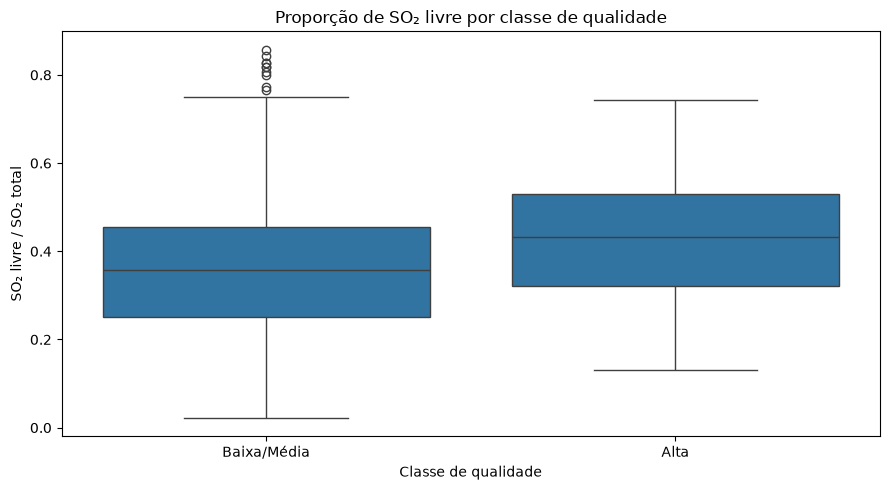

Correlação com alta qualidade: 0.1325


In [8]:

import matplotlib.pyplot as plt
import seaborn as sns

# Utilizar somente o conjunto de treinamento
dados_grafico = X_train_fe.copy()
dados_grafico["quality_class"] = y_train

# Criar gráfico comparativo
fig, ax = plt.subplots(figsize=(9, 5))

sns.boxplot(
    data=dados_grafico,
    x="quality_class",
    y="free_so2_ratio",
    order=[0, 1],
    ax=ax
)

ax.set_xticks(
    [0, 1],
    labels=["Baixa/Média", "Alta"]
)

ax.set_title(
    "Proporção de SO₂ livre por classe de qualidade"
)

ax.set_xlabel("Classe de qualidade")
ax.set_ylabel("SO₂ livre / SO₂ total")

plt.tight_layout()

# Salvar o gráfico no projeto
pasta_figuras = raiz / "results" / "figures"
pasta_figuras.mkdir(parents=True, exist_ok=True)

fig.savefig(
    pasta_figuras / "feature_so2_ratio.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# Calcular correlação da feature com a classe
correlacao = dados_grafico[
    ["free_so2_ratio", "quality_class"]
].corr().loc["free_so2_ratio", "quality_class"]

print(
    f"Correlação com alta qualidade: {correlacao:.4f}"
)


### Conclusão 14 — Avaliação da característica experimental

A análise da característica `free_so2_ratio`, desenvolvida a partir da proporção entre dióxido de enxofre livre e dióxido de enxofre total, identificou diferenças entre as classes de qualidade no conjunto de treinamento.

Os vinhos classificados como de alta qualidade apresentaram mediana de 43,33%, enquanto os de baixa/média qualidade apresentaram mediana de 35,71%.

Entretanto, a correlação de Pearson com a classificação binária foi de 0,1325, indicando associação linear positiva fraca. Os boxplots também evidenciaram sobreposição considerável entre as distribuições.

Dessa forma, a característica não apresentou evidências suficientes para justificar sua inclusão definitiva apenas com base na análise exploratória.

Optou-se por mantê-la como variável experimental, recomendando sua avaliação posterior por meio da comparação entre classificadores treinados com as 11 características originais e classificadores com a característica adicional.

A decisão final deverá considerar os resultados de validação dos modelos, sem utilizar o conjunto de teste para selecionar características.

## 2.6. Conclusões e passagem para a modelagem

**Entregas:**

1. `X_train` / `X_test`: 11 variáveis originais, sem escala; `y_train` / `y_test`: alvo binário.
2. `X_train_scaled` / `X_test_scaled`: versão padronizada, útil para inspeção ou ajuste simples com divisão fixa. Para **validação cruzada**, refazer a padronização dentro de `Pipeline`.
3. `X_train_fe` / `X_test_fe`: cenário **experimental** com `free_so2_ratio`. A associação com a classe é fraca (Pearson ≈ +0,1325, somente treino); não existe evidência de melhora preditiva sem avaliação cruzada.
4. `divisao_treino_teste.csv`: preserva índices e IDs dos conjuntos originais, para reconstruir a mesma divisão.
5. `standard_scaler.joblib`: parâmetros do pré-processamento base (11 variáveis), ajustados somente no treino.

**Limitações e decisões:** perfis duplicados foram mantidos, porém agrupados na divisão treino/teste (nenhum grupo compartilhado). Isso evita vazamento direto de perfis idênticos, embora repetições possam aumentar o peso de certos perfis. A proporção da classe 1 é de aproximadamente 14%; não se aplicou sobreamostragem. O teste final deverá ser utilizado **uma única vez depois da seleção de modelos e features no treinamento**.

Consulte também o documento `GUIA_INTEGRACAO_GRUPO.md`, entregue com estes notebooks.

In [9]:
# Auditoria final rápida (sem treinamento de modelos)
assert set(X_train.columns) == set(X_test.columns)
assert len(X_train) + len(X_test) == len(X)
assert set(grupos_id.iloc[idx_treino]).isdisjoint(set(grupos_id.iloc[idx_teste]))
assert X_train_scaled.shape == X_train.shape
assert X_test_scaled.shape == X_test.shape
assert X_train_fe.shape[1] == X.shape[1] + 1
assert (pasta_processados / "divisao_treino_teste.csv").is_file()
assert (pasta_artefatos / "standard_scaler.joblib").is_file()
print("Auditoria interna concluída: divisão, grupos, escala e arquivos consistentes.")

Auditoria interna concluída: divisão, grupos, escala e arquivos consistentes.
